# 04 — Gap Analysis

Combines vulnerability index and accessibility scores into a single gap surface.

```
gap_score = vulnerability_index × (1 − norm_accessibility)
```

High gap_score = high need, low service = priority zone.

**Output:** `data/processed/gap_surface.gpkg`

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from transit_gaps.accessibility import compute_gap_surface

In [2]:
# Load accessibility output (has vulnerability columns merged in)
acc_gdf = pd.read_parquet('../data/processed/accessibility_scores.parquet')
vuln_gdf = gpd.read_file('../data/processed/vulnerability_index.gpkg')

# Merge so we have both vulnerability_index and accessibility on same GDF
merged = vuln_gdf.merge(
    acc_gdf[['GEOID', 'accessibility_score', 'norm_accessibility']],
    on='GEOID', how='left'
)
merged.head()

,MTFCC,OID,GEOID,STATE,COUNTY,TRACT,BLKGRP,BASENAME,NAME,LSADC,...,pct_novehicle,pct_lowincome,norm_elderly,norm_unemployed,norm_novehicle,norm_lowincome,vulnerability_index,geometry,accessibility_score,norm_accessibility
0,G5030,208903716971219,530610527084,53,061,052708,4,4,Block Group 4,BG,...,0.010545,0.064428,0.171043,0.149163,0.019124,0.118667,0.114499,"MULTIPOLYGON (((-122.13555 48.06441, -122.1352...",19.682365,0.022624
1,G5030,20890919683484,530619400014,53,061,940001,4,4,Block Group 4,BG,...,0.010352,0.094855,0.212886,0.073031,0.018774,0.174710,0.119850,"MULTIPOLYGON (((-122.25525 48.10544, -122.2551...",0.000000,0.000000
2,G5030,20890918772702,530610531021,53,061,053102,1,1,Block Group 1,BG,...,0.115914,0.205601,0.207669,0.168672,0.210216,0.378688,0.241311,"MULTIPOLYGON (((-122.23812 48.15205, -122.2380...",1.407771,0.001618
3,G5030,20890919742081,530610531023,53,061,053102,3,3,Block Group 3,BG,...,0.000000,0.014829,0.311810,0.000000,0.000000,0.027313,0.084781,"MULTIPOLYGON (((-122.2892 48.15572, -122.28866...",0.889394,0.001022
4,G5030,20890918772691,530610533025,53,061,053302,5,5,Block Group 5,BG,...,0.108333,0.092379,0.492692,0.311014,0.196469,0.170149,0.292581,"MULTIPOLYGON (((-122.29536 48.23647, -122.2948...",0.000000,0.000000


In [3]:
gap_gdf = compute_gap_surface(
    acc_gdf=merged,
    out_path='../data/processed/gap_surface.gpkg'
)
gap_gdf[['GEOID', 'vulnerability_index', 'norm_accessibility', 'gap_score']].describe()

Saved gap surface → ../data/processed/gap_surface.gpkg  (575 block groups)


,vulnerability_index,norm_accessibility,gap_score
count,575.000000,575.000000,575.000000
mean,0.151651,0.049661,0.089500
std,0.082901,0.081082,0.057780
min,0.000000,0.000000,0.000000
25%,0.098295,0.001299,0.048420
50%,0.137095,0.018684,0.075988
75%,0.187922,0.064426,0.116696
max,0.587134,1.000000,0.354387


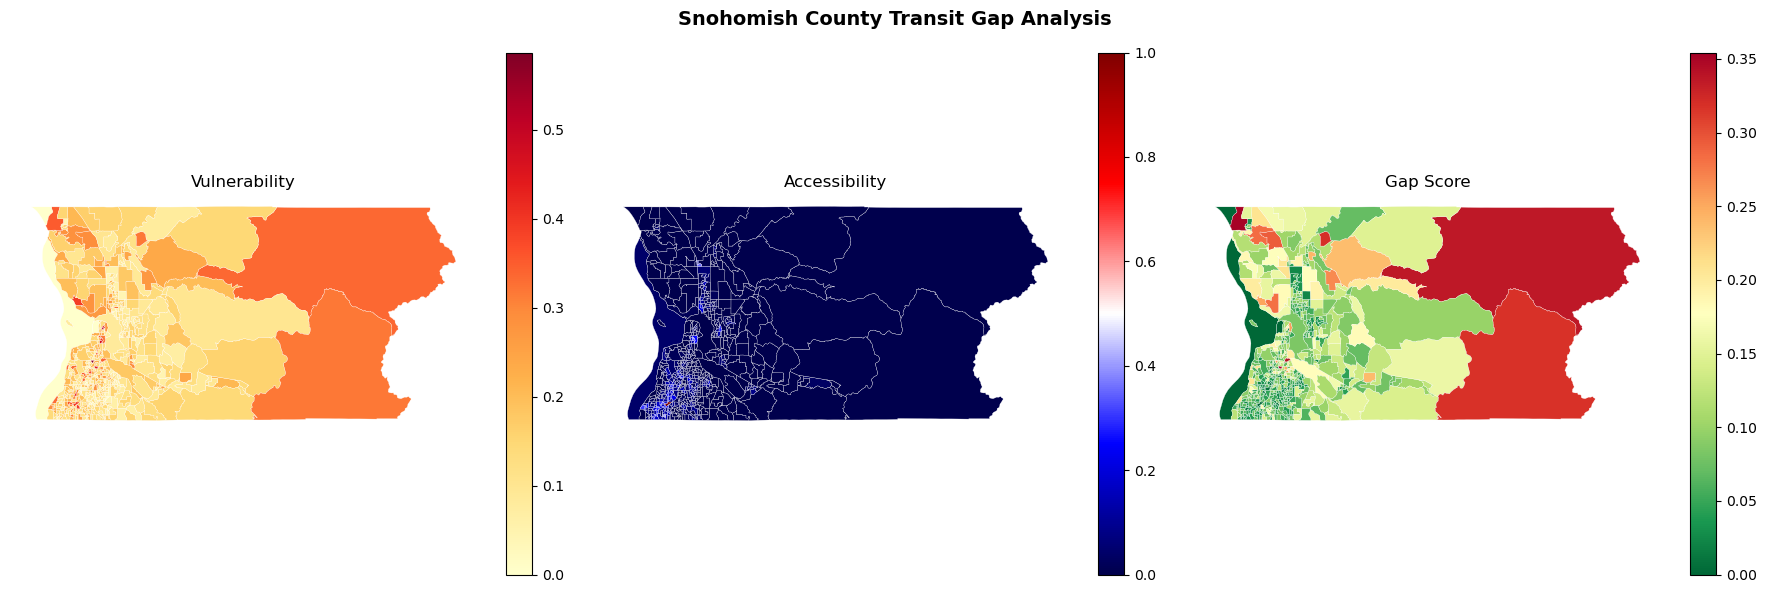

In [4]:
# QA: gap surface map
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, col, cmap, title in [
    (axes[0], 'vulnerability_index', 'YlOrRd', 'Vulnerability'),
    (axes[1], 'norm_accessibility', 'seismic', 'Accessibility'),
    (axes[2], 'gap_score', 'RdYlGn_r', 'Gap Score'),
]:
    gap_gdf.plot(column=col, cmap=cmap, legend=True,
                 linewidth=0.2, edgecolor='white', ax=ax)
    ax.set_title(title)
    ax.set_axis_off()

plt.suptitle('Snohomish County Transit Gap Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/outputs/maps/gap_analysis_qa.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Top 20 highest-gap block groups
top_gaps = gap_gdf.nlargest(20, 'gap_score')[[
    'GEOID', 'vulnerability_index', 'norm_accessibility', 'gap_score'
]]
print(top_gaps.to_string())

            GEOID  vulnerability_index  norm_accessibility  gap_score
344  530610418143             0.442895            0.003297   0.354387
285  530610533013             0.351982            0.000000   0.351982
54   530610416014             0.339786            0.000000   0.339786
16   530610537001             0.335330            0.000000   0.335330
233  530610535064             0.318737            0.000000   0.318737
396  530610538013             0.317049            0.000000   0.317049
4    530610533025             0.292581            0.000000   0.292581
429  530610533022             0.284421            0.000000   0.284421
476  530619400012             0.281909            0.000000   0.281909
273  530610535051             0.268525            0.000000   0.268525
296  530610419044             0.569591            0.046807   0.255667
98   530610402002             0.277465            0.000832   0.255156
53   530619400021             0.390875            0.011470   0.252533
339  530610416054   

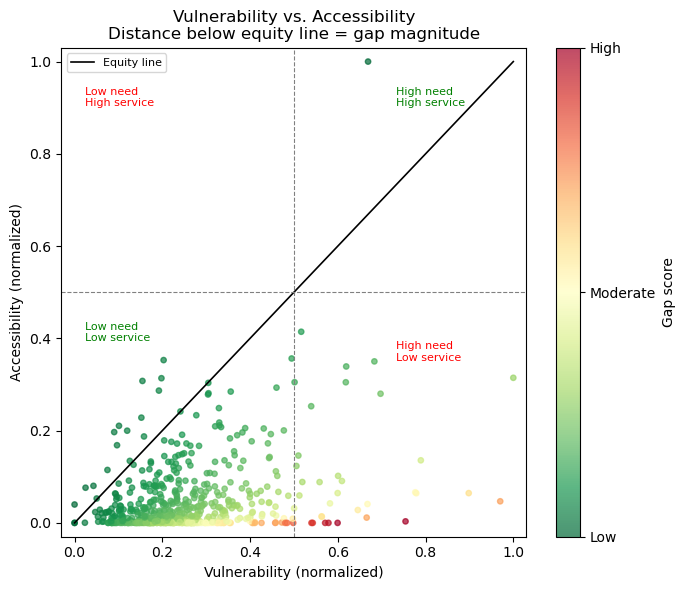

In [15]:
# Scatter: vulnerability vs. accessibility — equity gap view
# Normalize both axes to [0,1] so they share the same scale
v = gap_gdf['vulnerability_index']
a = gap_gdf['norm_accessibility']
vuln_n = (v - v.min()) / (v.max() - v.min())
acc_n  = (a - a.min()) / (a.max() - a.min())

PAD = 0.03
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(
    vuln_n, acc_n,
    c=gap_gdf['gap_score'],
    cmap='RdYlGn_r', s=15, alpha=0.7
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_ticks([gap_gdf['gap_score'].min(),
                (gap_gdf['gap_score'].min() + gap_gdf['gap_score'].max()) / 2,
                gap_gdf['gap_score'].max()])
cbar.set_ticklabels(['Low', 'Moderate', 'High'], rotation = 0)
cbar.set_label('Gap score')


ax.plot([0, 1], [0, 1], color='black', lw=1.2, ls='-', label='Equity line')

# Quadrant dividers at 0.5
ax.axvline(0.5, color='gray', lw=0.8, ls='--')
ax.axhline(0.5, color='gray', lw=0.8, ls='--')

ax.set_xlim(-PAD, 1 + PAD)
ax.set_ylim(-PAD, 1 + PAD)
ax.set_xlabel('Vulnerability (normalized)')
ax.set_ylabel('Accessibility (normalized)')
ax.set_title('Vulnerability vs. Accessibility\nDistance below equity line = gap magnitude')
ax.text(0.72, 0.92, 'High need\nHigh service', transform=ax.transAxes,
        color='green', fontsize=8, va='top')

ax.text(0.05, 0.92, 'Low need\nHigh service', transform=ax.transAxes,
        color='red', fontsize=8, va='top')

ax.text(0.72, 0.40, 'High need\nLow service', transform=ax.transAxes,
        color='red', fontsize=8, va='top')
ax.text(0.05, 0.40, 'Low need\nLow service', transform=ax.transAxes,
        color='green', fontsize=8)
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig('../data/outputs/vulnerability_accessibility.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
import numpy as np

# Recompute normalized axes (same as scatter cell)
v = gap_gdf['vulnerability_index']
a = gap_gdf['norm_accessibility']
vuln_n = (v - v.min()) / (v.max() - v.min())
acc_n  = (a - a.min()) / (a.max() - a.min())

# Signed perpendicular distance from equity line y = x
# X = vulnerability, Y = accessibility
# Positive: below line (high need, low service) — underserved / gap
# Negative: above line (low need, high service) — over-served
gap_gdf['equity_distance'] = (vuln_n - acc_n) / np.sqrt(2)

cols = ['GEOID', 'vulnerability_index', 'norm_accessibility', 'gap_score', 'equity_distance']

print('=== Top 10 underserved (furthest below equity line) ===')
print(gap_gdf.nlargest(10, 'equity_distance')[cols].to_string(index=False))

print()
print('=== Top 10 over-served (furthest above equity line) ===')
print(gap_gdf.nsmallest(10, 'equity_distance')[cols].to_string(index=False))

=== Top 10 underserved (furthest below equity line) ===
       GEOID  vulnerability_index  norm_accessibility  gap_score  equity_distance
530610419044             0.569591            0.046807   0.255667         0.652882
530610402004             0.527461            0.064563   0.212213         0.589587
530610418143             0.442895            0.003297   0.354387         0.531063
530610402005             0.457285            0.064288   0.184263         0.505267
530610419043             0.455919            0.066338   0.181635         0.502171
530610407001             0.587134            0.314508   0.100109         0.484716
530619400021             0.390875            0.011470   0.252533         0.462634
530610410001             0.463371            0.135617   0.136256         0.462159
530610519292             0.391976            0.040882   0.183578         0.443162
530610418091             0.379028            0.027890   0.198218         0.436756

=== Top 10 over-served (furthest above eq

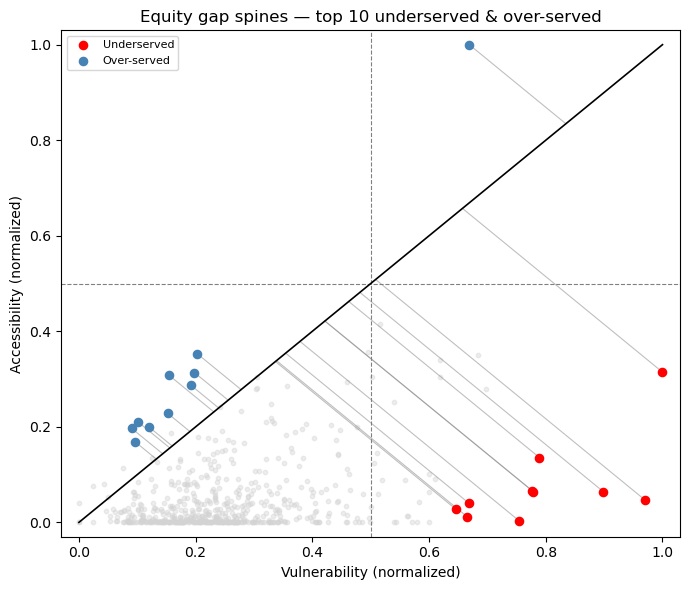

In [8]:
# Equity spine plot — top 10 underserved & top 10 over-served
# Perpendicular foot of point (x0, y0) on y=x is ((x0+y0)/2, (x0+y0)/2)

v = gap_gdf['vulnerability_index']
a = gap_gdf['norm_accessibility']
vuln_n = (v - v.min()) / (v.max() - v.min())
acc_n  = (a - a.min()) / (a.max() - a.min())

top_under      = gap_gdf.nlargest(10, 'equity_distance').index
top_overserved = gap_gdf.nsmallest(10, 'equity_distance').index
highlight      = top_under.union(top_overserved)

PAD = 0.03
fig, ax = plt.subplots(figsize=(7, 6))

# Background: all points, faint
ax.scatter(vuln_n, acc_n, c='lightgray', s=10, alpha=0.4, zorder=1)

# Spines: gray lines from point to foot on y=x
for idx in highlight:
    x0, y0 = vuln_n[idx], acc_n[idx]
    foot = (x0 + y0) / 2
    ax.plot([x0, foot], [y0, foot], color='gray', lw=0.8, alpha=0.5, zorder=2)

# Highlighted points
ax.scatter(vuln_n[top_under],      acc_n[top_under],
           c='red',       s=35, zorder=3, label='Underserved')
ax.scatter(vuln_n[top_overserved], acc_n[top_overserved],
           c='steelblue', s=35, zorder=3, label='Over-served')

# Equity diagonal
ax.plot([0, 1], [0, 1], color='black', lw=1.2, zorder=4)

# Quadrant dividers
ax.axvline(0.5, color='gray', lw=0.8, ls='--', zorder=1)
ax.axhline(0.5, color='gray', lw=0.8, ls='--', zorder=1)

ax.set_xlim(-PAD, 1 + PAD)
ax.set_ylim(-PAD, 1 + PAD)
ax.set_xlabel('Vulnerability (normalized)')
ax.set_ylabel('Accessibility (normalized)')
ax.set_title('Equity gap spines — top 10 underserved & over-served')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig('../data/outputs/equity_spines.png', dpi=150, bbox_inches='tight')
plt.show()

           GEOID  vulnerability_index  norm_accessibility  gap_score  equity_distance  priority
1   530610418143             0.442895            0.003297   0.354387         0.531063  0.906577
2   530610419044             0.569591            0.046807   0.255667         0.652882  0.855299
3   530610533013             0.351982            0.000000   0.351982         0.423905  0.820873
4   530610416014             0.339786            0.000000   0.339786         0.409217  0.791731
5   530610537001             0.335330            0.000000   0.335330         0.403850  0.781084
6   530610402004             0.527461            0.064563   0.212213         0.589587  0.743065
7   530610535064             0.318737            0.000000   0.318737         0.383867  0.741437
8   530610538013             0.317049            0.000000   0.317049         0.381834  0.737404
9   530619400021             0.390875            0.011470   0.252533         0.462634  0.704805
10  530610533025             0.292581   

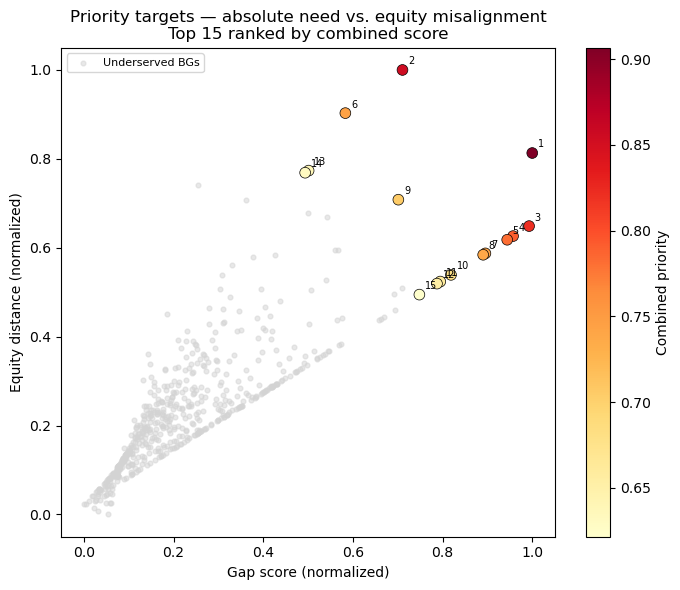

In [9]:
# 2D priority ranking: high gap_score AND high equity_distance
# Only underserved (equity_distance > 0) are campaign targets
under = gap_gdf[gap_gdf['equity_distance'] > 0].copy()

# Normalize each metric to [0,1] within the underserved population
under['gap_score_n'] = (under['gap_score'] - under['gap_score'].min()) / \
                        (under['gap_score'].max() - under['gap_score'].min())
under['equity_dist_n'] = (under['equity_distance'] - under['equity_distance'].min()) / \
                          (under['equity_distance'].max() - under['equity_distance'].min())

# Combined priority: mean of both normalized scores
under['priority'] = (under['gap_score_n'] + under['equity_dist_n']) / 2

cols = ['GEOID', 'vulnerability_index', 'norm_accessibility',
        'gap_score', 'equity_distance', 'priority']
top = under.nlargest(15, 'priority')[cols].reset_index(drop=True)
top.index += 1
print(top.to_string())

# Scatter: gap_score vs equity_distance, top 15 highlighted
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(under['gap_score_n'], under['equity_dist_n'],
           c='lightgray', s=12, alpha=0.5, zorder=1, label='Underserved BGs')

top_idx = under.nlargest(15, 'priority').index
sc = ax.scatter(under.loc[top_idx, 'gap_score_n'],
                under.loc[top_idx, 'equity_dist_n'],
                c=under.loc[top_idx, 'priority'],
                cmap='YlOrRd', s=60, zorder=2, edgecolors='black', lw=0.5)
plt.colorbar(sc, ax=ax, label='Combined priority')

# Label rank numbers
for rank, idx in enumerate(under.nlargest(15, 'priority').index, 1):
    ax.annotate(str(rank),
                xy=(under.loc[idx, 'gap_score_n'], under.loc[idx, 'equity_dist_n']),
                xytext=(4, 4), textcoords='offset points', fontsize=7)

ax.set_xlabel('Gap score (normalized)')
ax.set_ylabel('Equity distance (normalized)')
ax.set_title('Priority targets — absolute need vs. equity misalignment\n'
             'Top 15 ranked by combined score')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../data/outputs/priority_targets.png', dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_138587/740003998.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap    = plt.cm.get_cmap('magma', n_bins)


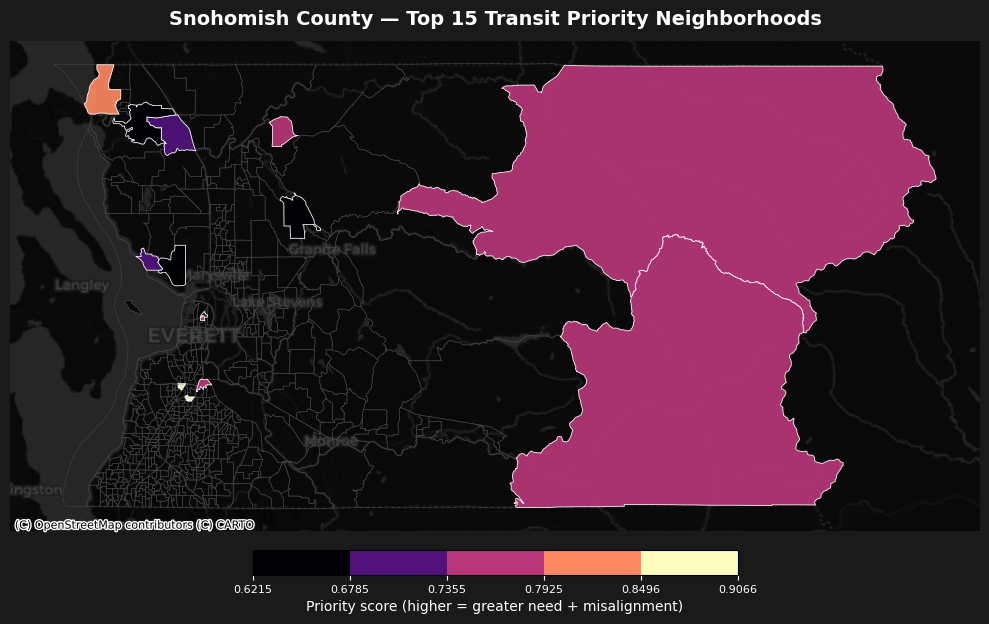

In [17]:
import contextily as ctx
import matplotlib.colors as mcolors
import numpy as np

# Recompute priority on underserved subset
under = gap_gdf[gap_gdf['equity_distance'] > 0].copy()
under['gap_score_n']   = (under['gap_score'] - under['gap_score'].min()) / \
                          (under['gap_score'].max() - under['gap_score'].min())
under['equity_dist_n'] = (under['equity_distance'] - under['equity_distance'].min()) / \
                          (under['equity_distance'].max() - under['equity_distance'].min())
under['priority']      = (under['gap_score_n'] + under['equity_dist_n']) / 2
top15_idx = under.nlargest(15, 'priority').index

# Project to web mercator for contextily basemap
bg_web  = gap_gdf.to_crs('EPSG:3857')
top_web = bg_web.loc[top15_idx].copy()
top_web['priority'] = under.loc[top15_idx, 'priority'].values

# Discrete bins: 5 equal steps across the top-15 priority range
n_bins  = 5
p_vals  = top_web['priority']
bounds  = np.linspace(p_vals.min(), p_vals.max(), n_bins + 1)
cmap    = plt.cm.get_cmap('magma', n_bins)
norm    = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

fig, ax = plt.subplots(figsize=(10, 10))
fig.patch.set_facecolor('#1a1a1a')
ax.set_facecolor('#1a1a1a')

# All block groups — outline only
bg_web.plot(ax=ax, facecolor='none', edgecolor='#444444', linewidth=0.4, zorder=2)

# Priority neighborhoods — discrete magma steps
top_web.plot(
    column='priority', cmap=cmap, norm=norm,
    ax=ax, edgecolor='white', linewidth=0.6, zorder=3, alpha=0.92
)

# Colorbar — discrete steps, white text
sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', shrink=0.5,
                    pad=0.02, ticks=bounds, spacing='uniform')
cbar.set_label('Priority score (higher = greater need + misalignment)', color='white')
cbar.ax.xaxis.set_tick_params(color='white')
plt.setp(cbar.ax.get_xticklabels(), color='white', fontsize=8)

# Basemap
try:
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.DarkMatter, zoom='auto')
except Exception as e:
    print(f'Basemap unavailable: {e}')

ax.set_axis_off()
ax.set_title(
    'Snohomish County — Top 15 Transit Priority Neighborhoods',
    fontsize=14, fontweight='bold', pad=12, color='white'
)

plt.tight_layout()
plt.savefig('../data/outputs/priority_map.png', dpi=200, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()